# 03 - Predictive Model, Explainability and Fairness (H5, H6)
**Fair Mortgage Approval Decisions - ADS End-Term Project, Group 8**  |  BADIR stage: *Insights -> Recommendation*

**Question for the stakeholder (credit-risk team):** can a model reproduce past approve/deny decisions well, what drives it, and does it treat groups differently? The model scores *how likely this application is to be denied*; a threshold turns the score into a recommendation.

**Course methods used here:** gradient boosting (LightGBM), time-based validation, hyperparameter search, calibration, SHAP (explainable AI), fairness metrics and a bias-mitigation step (reweighing).

### Design choices (be ready to explain each)
| Choice | Why |
|---|---|
| **Train 2018-2022, test 2023** | Mimics real use: learn from the past, score the future. No random shuffling across years. |
| **Race, ethnicity, sex, age are NOT model inputs** | Fair-lending law (ECOA) forbids using them. We only use them afterwards to *audit* the model. |
| **Leakage columns excluded** | `interest_rate`, `rate_spread`, fees, etc. exist only for approved loans (shown in notebook 01). Using them would be cheating. |
| **Tract minority share excluded** | It is a near-proxy for race. Income-based area variables are kept. |
| **H5 AUC judged on complete cases** | Missing DTI / income often means the application was closed early (usually a denial). A model can learn 'missing = denied', which flatters the AUC. The complete-case AUC is the honest number. |

**Decision rules (fixed in advance)**
* **H5 Supported** if test AUC > 0.80 (complete cases, 2023) **and** DTI and LTV are both among the 3 most important features (mean |SHAP|). *Not supported* if AUC <= 0.80 or neither feature is in the top 3. Otherwise *Inconclusive*.
* **H6 Supported** if, for any group with at least 1,000 test applications, any of overall error rate / false-positive rate / false-negative rate is **more than 5 percentage points** different from White applicants **and** that difference is statistically significant (95% CI above 0).

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy import stats
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, roc_curve,
                             precision_score, recall_score, f1_score)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
MODELS = ROOT / "models"; MODELS.mkdir(exist_ok=True)
SEED = 42

BLUE, ORANGE, GREEN, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True})

def finish(ax, title, subtitle=None, name=None):
    ax.set_title(title, loc="left", fontsize=12, fontweight="bold", pad=22 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, fontsize=9, color=MUTED, va="bottom")
    plt.tight_layout()
    if name:
        plt.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

## 1. Features and train / test split

In [2]:
NUMERIC = ["dti_mid", "loan_to_value_ratio", "income_w", "loan_amount_w", "property_value_w", "loan_to_income",
           "loan_term", "total_units", "tract_to_msa_income_percentage", "acs_median_hh_income_real",
           "acs_poverty_rate", "acs_unemployment_rate"]
CATEG = ["loan_type", "derived_loan_product_type", "derived_dwelling_category", "construction_method", "preapproval"]
FEATURES = NUMERIC + CATEG
AUDIT = ["derived_race", "derived_sex"]                     # used ONLY to audit, never as inputs

df = pd.read_parquet(ROOT / "data" / "processed" / "ssot.parquet", columns=FEATURES + AUDIT + ["denied", "year", "dti_missing"])
for c in CATEG:
    df[c] = df[c].astype("string").fillna("missing").astype("category")
race_map = {"White": "White", "Black or African American": "Black", "Asian": "Asian", "Joint": "Joint",
            "Race Not Available": "Not available"}
df["race_grp"] = df["derived_race"].map(race_map).fillna("Other / 2+ races")
df["complete"] = df[["dti_mid", "loan_to_value_ratio", "income_w"]].notna().all(axis=1)

train = df[df.year <= 2021]; valid = df[df.year == 2022]; fit_all = df[df.year <= 2022]; test = df[df.year == 2023]
print(f"Features ({len(FEATURES)}): {FEATURES}")
for name, d in [("train 2018-2021", train), ("validation 2022", valid), ("final fit 2018-2022", fit_all), ("test 2023", test)]:
    print(f"{name:20s} rows {len(d):>9,}   denial rate {d.denied.mean():.1%}   complete cases {d.complete.mean():.1%}")

Features (17): ['dti_mid', 'loan_to_value_ratio', 'income_w', 'loan_amount_w', 'property_value_w', 'loan_to_income', 'loan_term', 'total_units', 'tract_to_msa_income_percentage', 'acs_median_hh_income_real', 'acs_poverty_rate', 'acs_unemployment_rate', 'loan_type', 'derived_loan_product_type', 'derived_dwelling_category', 'construction_method', 'preapproval']
train 2018-2021      rows   934,254   denial rate 12.4%   complete cases 89.4%
validation 2022      rows   213,413   denial rate 13.8%   complete cases 88.7%
final fit 2018-2022  rows 1,147,667   denial rate 12.7%   complete cases 89.3%
test 2023            rows   172,560   denial rate 15.3%   complete cases 88.1%


## 2. Baselines
* **The lender's current rule of thumb:** 'DTI above 43% -> deny'. We use DTI itself as the score.
* **Logistic regression:** a simple, explainable benchmark.

In [3]:
def auc(y, s):
    return roc_auc_score(y, s)

yt = test.denied.values
rule_score = test.dti_mid.fillna(test.dti_mid.median())
print(f"Rule of thumb (DTI as score)  AUC on 2023: {auc(yt, rule_score):.3f}")

def lr_matrix(d, med):
    X = d[NUMERIC].copy()
    miss = X.isna().astype(int).add_suffix("_missing")
    X = X.fillna(med)
    for c in ["income_w", "loan_amount_w", "property_value_w"]:
        X[c] = np.log(X[c])
    return pd.concat([X, miss, pd.get_dummies(d[CATEG].astype(str), drop_first=False)], axis=1)

med = fit_all[NUMERIC].median()
Xl = lr_matrix(fit_all, med); Xl_t = lr_matrix(test, med).reindex(columns=Xl.columns, fill_value=0)
mu, sd = Xl.mean(), Xl.std().replace(0, 1)
lr = LogisticRegression(max_iter=300).fit(((Xl - mu) / sd).astype("float32"), fit_all.denied)
p_lr = lr.predict_proba(((Xl_t - mu) / sd).astype("float32"))[:, 1]
print(f"Logistic regression           AUC on 2023: {auc(yt, p_lr):.3f}")

Rule of thumb (DTI as score)  AUC on 2023: 0.668


Logistic regression           AUC on 2023: 0.833


## 3. Gradient boosting: hyperparameter search
We try 6 random settings. Each is trained on 2018-2021 and scored on 2022 (AUC); early stopping picks the number of trees. **The 2023 test set is not touched here.**

In [4]:
def make_set(d, w=None):
    return lgb.Dataset(d[FEATURES], d.denied, weight=w, categorical_feature=CATEG, free_raw_data=False)

rng = np.random.default_rng(SEED)
space = dict(num_leaves=[31, 63, 127], min_child_samples=[50, 200, 500], feature_fraction=[0.7, 0.9, 1.0], lambda_l2=[0, 5, 20])
trials = []
for t in range(6):
    p = {k: rng.choice(v).item() for k, v in space.items()}
    params = dict(objective="binary", metric="auc", learning_rate=0.08, bagging_fraction=0.8, bagging_freq=1,
                  seed=SEED, verbose=-1, **p)
    b = lgb.train(params, make_set(train), num_boost_round=800, valid_sets=[make_set(valid)],
                  callbacks=[lgb.early_stopping(40, verbose=False)])
    trials.append(dict(**p, trees=b.best_iteration, val_auc=b.best_score["valid_0"]["auc"]))
    print(trials[-1])
tr = pd.DataFrame(trials).sort_values("val_auc", ascending=False)
display(tr.round(4))
best = tr.iloc[0]
BEST = dict(objective="binary", metric="auc", learning_rate=0.08, bagging_fraction=0.8, bagging_freq=1, seed=SEED, verbose=-1,
            num_leaves=int(best.num_leaves), min_child_samples=int(best.min_child_samples),
            feature_fraction=float(best.feature_fraction), lambda_l2=float(best.lambda_l2))
N_TREES = int(best.trees * 1.1)     # a little more data in the final fit -> slightly more trees
print("Chosen:", BEST, "| trees:", N_TREES)

{'num_leaves': 31, 'min_child_samples': 500, 'feature_fraction': 0.9, 'lambda_l2': 5, 'trees': 354, 'val_auc': np.float64(0.8646895798873825)}


{'num_leaves': 63, 'min_child_samples': 500, 'feature_fraction': 0.7, 'lambda_l2': 20, 'trees': 264, 'val_auc': np.float64(0.8650562105927961)}


{'num_leaves': 31, 'min_child_samples': 50, 'feature_fraction': 0.9, 'lambda_l2': 20, 'trees': 517, 'val_auc': np.float64(0.8649534289300477)}


{'num_leaves': 127, 'min_child_samples': 500, 'feature_fraction': 1.0, 'lambda_l2': 20, 'trees': 137, 'val_auc': np.float64(0.8645699138641947)}


{'num_leaves': 63, 'min_child_samples': 50, 'feature_fraction': 1.0, 'lambda_l2': 5, 'trees': 278, 'val_auc': np.float64(0.8650999327295684)}


{'num_leaves': 63, 'min_child_samples': 200, 'feature_fraction': 0.7, 'lambda_l2': 20, 'trees': 163, 'val_auc': np.float64(0.8648269204239891)}


,num_leaves,min_child_samples,feature_fraction,lambda_l2,trees,val_auc
4,63,50,1.0,5,278,0.8651
1,63,500,0.7,20,264,0.8651
2,31,50,0.9,20,517,0.8650
5,63,200,0.7,20,163,0.8648
0,31,500,0.9,5,354,0.8647
3,127,500,1.0,20,137,0.8646


Chosen: {'objective': 'binary', 'metric': 'auc', 'learning_rate': 0.08, 'bagging_fraction': 0.8, 'bagging_freq': 1, 'seed': 42, 'verbose': -1, 'num_leaves': 63, 'min_child_samples': 50, 'feature_fraction': 1.0, 'lambda_l2': 5.0} | trees: 305


## 4. Final model: evaluation on 2023 (unseen year)
The final model is fit on 2018-2022. The decision threshold is chosen on **2022 validation** predictions (maximise F1), never on the test year.

In [5]:
# threshold from the tuning model (trained 2018-2021, scored on 2022)
tune = lgb.train(BEST, make_set(train), num_boost_round=int(best.trees))
pv = tune.predict(valid[FEATURES])
grid = np.linspace(0.05, 0.6, 56)
f1s = [f1_score(valid.denied, pv >= t) for t in grid]
THR = float(grid[int(np.argmax(f1s))])
print(f"Chosen threshold (max F1 on 2022): {THR:.2f}")

final = lgb.train(BEST, make_set(fit_all), num_boost_round=N_TREES)
test = test.copy()
test["p"] = final.predict(test[FEATURES])
test["pred"] = (test.p >= THR).astype(int)

def metrics(d, label):
    y, p, pr = d.denied.values, d.p.values, d.pred.values
    return dict(subset=label, rows=len(d), auc=auc(y, p), pr_auc=average_precision_score(y, p), brier=brier_score_loss(y, p),
                precision=precision_score(y, pr), recall=recall_score(y, pr), accuracy=(pr == y).mean())
res = pd.DataFrame([metrics(test, "all test rows"), metrics(test[test.complete], "complete cases only"),
                    metrics(test[~test.complete], "rows with missing DTI/LTV/income")]).set_index("subset")
display(res.round(3))

rng2 = np.random.default_rng(SEED)
tc = test[test.complete]
boot = [auc(tc.denied.values[i], tc.p.values[i]) for i in (rng2.integers(0, len(tc), len(tc)) for _ in range(100))]
AUC_C = res.loc["complete cases only", "auc"]; AUC_LO, AUC_HI = np.percentile(boot, [2.5, 97.5])
print(f"Complete-case AUC {AUC_C:.3f} (95% bootstrap CI {AUC_LO:.3f}-{AUC_HI:.3f});  baselines on same rows: "
      f"DTI rule {auc(tc.denied, tc.dti_mid):.3f}, logistic {auc(tc.denied.values, p_lr[test.complete.values]):.3f}")

Chosen threshold (max F1 on 2022): 0.31


,rows,auc,pr_auc,brier,precision,recall,accuracy
subset,,,,,,,
all test rows,172560,0.880,0.749,0.067,0.756,0.641,0.914
complete cases only,152017,0.825,0.587,0.062,0.722,0.453,0.925
rows with missing DTI/LTV/income,20543,0.927,0.934,0.110,0.783,0.925,0.831


Complete-case AUC 0.825 (95% bootstrap CI 0.821-0.830);  baselines on same rows: DTI rule 0.682, logistic 0.770


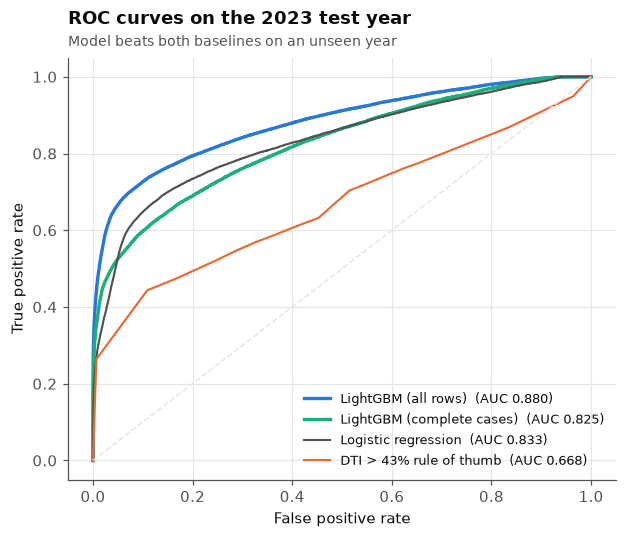

In [6]:
fig, ax = plt.subplots(figsize=(5.8, 5))
for lab, y, s, col, lw in [("LightGBM (all rows)", test.denied, test.p, BLUE, 2.2),
                           ("LightGBM (complete cases)", tc.denied, tc.p, GREEN, 2.2),
                           ("Logistic regression", test.denied, p_lr, MUTED, 1.4),
                           ("DTI > 43% rule of thumb", test.denied, rule_score, ORANGE, 1.4)]:
    f, t, _ = roc_curve(y, s); ax.plot(f, t, color=col, lw=lw, label=f"{lab}  (AUC {auc(y, s):.3f})")
ax.plot([0, 1], [0, 1], color=GRID, lw=1, ls="--"); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.legend(frameon=False, loc="lower right", fontsize=8.5)
finish(ax, "ROC curves on the 2023 test year", "Model beats both baselines on an unseen year", "14_roc")

### Calibration
Does a predicted '30% chance of denial' really mean ~30% were denied? We compare the raw model with an **isotonic recalibration** fitted on 2022 validation data.

Brier score (lower is better): raw 0.0675  |  calibrated 0.0675


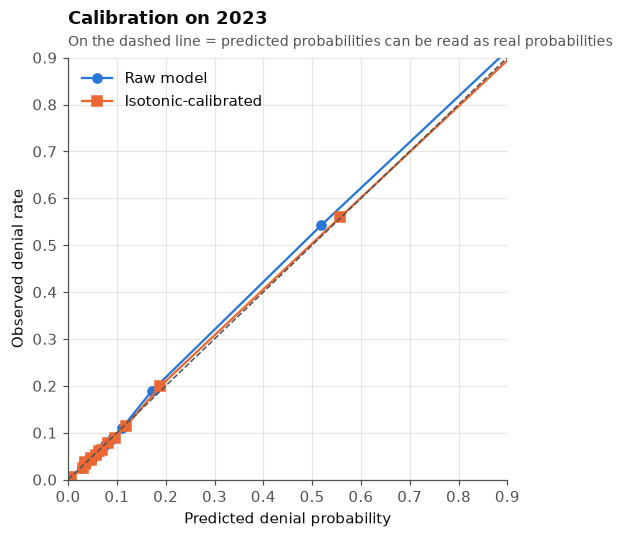

In [7]:
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(pv, valid.denied)
test["p_cal"] = iso.predict(test.p)
print(f"Brier score (lower is better): raw {brier_score_loss(test.denied, test.p):.4f}  |  calibrated {brier_score_loss(test.denied, test.p_cal):.4f}")

fig, ax = plt.subplots(figsize=(5.5, 5))
for lab, col, mk in [("p", BLUE, "o"), ("p_cal", ORANGE, "s")]:
    g = test.groupby(pd.qcut(test[lab], 15, duplicates="drop"), observed=True).agg(pred=(lab, "mean"), obs=("denied", "mean"))
    ax.plot(g.pred, g.obs, marker=mk, color=col, lw=1.5, ms=6, label="Raw model" if lab == "p" else "Isotonic-calibrated")
ax.plot([0, 1], [0, 1], color=MUTED, ls="--", lw=1); ax.set_xlim(0, 0.9); ax.set_ylim(0, 0.9)
ax.set_xlabel("Predicted denial probability"); ax.set_ylabel("Observed denial rate"); ax.legend(frameon=False)
finish(ax, "Calibration on 2023", "On the dashed line = predicted probabilities can be read as real probabilities", "15_calibration")

## 5. What drives the model? SHAP (H5)
SHAP assigns every feature a contribution to each individual prediction. **Mean |SHAP|** = how much a feature moves predictions on average. We use LightGBM's built-in exact TreeSHAP (`pred_contrib=True`) on 50,000 complete-case test rows.

preapproval                       28.4
dti_mid                           18.4
property_value_w                  14.2
loan_amount_w                      7.5
derived_dwelling_category          7.1
loan_to_value_ratio                5.9
loan_type                          4.5
loan_term                          2.5
income_w                           2.3
tract_to_msa_income_percentage     2.1
acs_poverty_rate                   2.0
loan_to_income                     1.7
acs_unemployment_rate              1.6
acs_median_hh_income_real          1.3
total_units                        0.5
derived_loan_product_type          0.0
construction_method                0.0


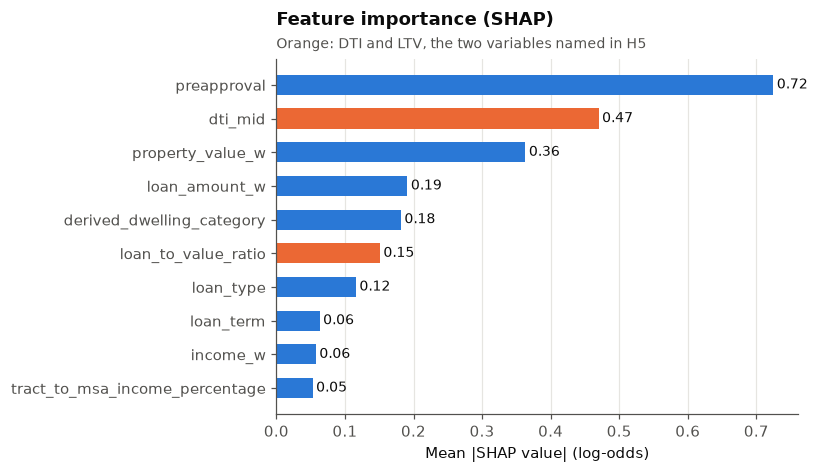

In [8]:
sv_rows = tc.sample(50_000, random_state=SEED)
contrib = final.predict(sv_rows[FEATURES], pred_contrib=True)            # last column = baseline value
sv = pd.DataFrame(contrib[:, :-1], columns=FEATURES, index=sv_rows.index)
imp = sv.abs().mean().sort_values(ascending=False)
print((imp / imp.sum() * 100).round(1).to_string())

top = imp.head(10)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 4.4))
ax.barh(top.index, top.values, color=[ORANGE if i in ("dti_mid", "loan_to_value_ratio") else BLUE for i in top.index], height=0.6)
for i, v in enumerate(top.values):
    ax.text(v + 0.005, i, f"{v:.2f}", va="center", fontsize=9)
ax.set_xlabel("Mean |SHAP value| (log-odds)"); ax.grid(axis="y", visible=False)
finish(ax, "Feature importance (SHAP)", "Orange: DTI and LTV, the two variables named in H5", "16_shap_importance")

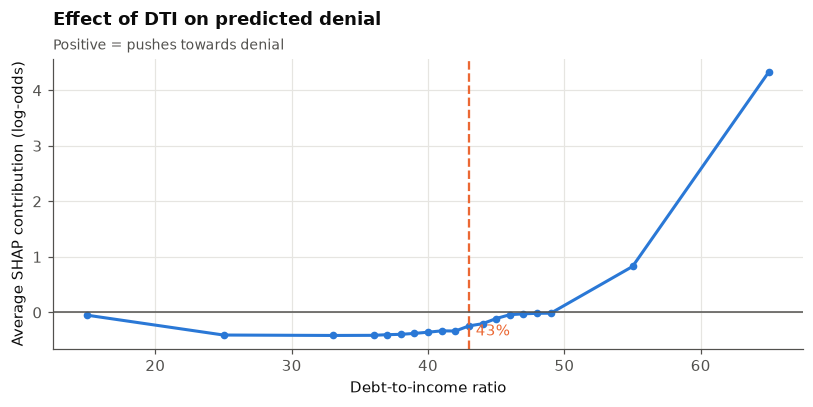

In [9]:
# How does DTI move the prediction? (links back to H1 - a smooth rise, or a jump at 43?)
x = sv_rows.dti_mid.round().clip(10, 70)
dep = pd.DataFrame({"dti": x.values, "shap": sv.dti_mid.values}).groupby("dti").shap.agg(["mean", "size"])
dep = dep[dep["size"] >= 200]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(dep.index, dep["mean"], color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(43, color=ORANGE, lw=1.5, ls="--"); ax.text(43.5, dep["mean"].min(), "43%", color=ORANGE)
ax.axhline(0, color=MUTED, lw=1); ax.set_xlabel("Debt-to-income ratio"); ax.set_ylabel("Average SHAP contribution (log-odds)")
finish(ax, "Effect of DTI on predicted denial", "Positive = pushes towards denial", "17_shap_dti")

In [10]:
top3 = list(imp.index[:3])
auc_ok = AUC_C > 0.80
n_hit = int("dti_mid" in top3) + int("loan_to_value_ratio" in top3)
if auc_ok and n_hit == 2: V5 = "Supported"
elif (not auc_ok) or n_hit == 0: V5 = "Not supported"
else: V5 = "Inconclusive"
print(f"Complete-case AUC {AUC_C:.3f} > 0.80: {auc_ok} | top-3 features: {top3} (DTI and LTV in top 3: {n_hit}/2)  ->  H5: {V5}")

Complete-case AUC 0.825 > 0.80: True | top-3 features: ['preapproval', 'dti_mid', 'property_value_w'] (DTI and LTV in top 3: 1/2)  ->  H5: Inconclusive


In [11]:
# Sensitivity: 'preapproval' marks applications that are pre-approval REQUESTS - a type of application, not a
# risk trait of the borrower - and it came out as the single most important feature. Does H5 change without it?
FEAT2 = [f for f in FEATURES if f != "preapproval"]; CAT2 = [c for c in CATEG if c != "preapproval"]
m2 = lgb.train(BEST, lgb.Dataset(fit_all[FEAT2], fit_all.denied, categorical_feature=CAT2), num_boost_round=N_TREES)
S_AUC = auc(tc.denied, m2.predict(tc[FEAT2]))
c2 = m2.predict(tc.sample(50_000, random_state=SEED)[FEAT2], pred_contrib=True)
imp2 = pd.DataFrame(c2[:, :-1], columns=FEAT2).abs().mean().sort_values(ascending=False)
S_TOP3 = list(imp2.index[:3])
print(f"Without 'preapproval': complete-case AUC {S_AUC:.3f}; top-3 features {S_TOP3}")
print((imp2 / imp2.sum() * 100).round(1).head(6).to_string())
print("The H5 verdict above stays as pre-registered; this shows how sensitive it is to one feature.")

Without 'preapproval': complete-case AUC 0.814; top-3 features ['dti_mid', 'property_value_w', 'loan_amount_w']
dti_mid                      25.9
property_value_w             19.8
loan_amount_w                10.2
derived_dwelling_category     9.8
loan_to_value_ratio           8.1
loan_type                     6.7
The H5 verdict above stays as pre-registered; this shows how sensitive it is to one feature.


### H5 - extra check (not part of the pre-set rule): importance by *group* of features
H5 says 'DTI and LTV matter most'. One feature at a time they compete with several size variables; grouped, we can ask whether **leverage** (DTI, LTV, loan-to-income) carries more of the model than **size** (property value, loan amount, income). Shares of total mean |SHAP|, with and without `preapproval`.

In [12]:
GROUPS = {"Leverage (DTI, LTV, loan-to-income)": ["dti_mid", "loan_to_value_ratio", "loan_to_income"],
          "Size (property value, loan amount, income)": ["property_value_w", "loan_amount_w", "income_w"],
          "Neighbourhood (tract income, poverty, unemployment)": ["tract_to_msa_income_percentage", "acs_median_hh_income_real",
                                                                  "acs_poverty_rate", "acs_unemployment_rate"],
          "Product (loan type, dwelling, term, units, ...)": ["loan_type", "derived_loan_product_type", "derived_dwelling_category",
                                                             "construction_method", "loan_term", "total_units"],
          "Application type (preapproval flag)": ["preapproval"]}
def grp_share(series):
    tot = series.sum()
    return {g: 100 * series.reindex(cols).fillna(0).sum() / tot for g, cols in GROUPS.items()}
gt = pd.DataFrame({"with preapproval (%)": grp_share(imp), "without preapproval (%)": grp_share(imp2)}).round(1)
display(gt)

,with preapproval (%),without preapproval (%)
"Leverage (DTI, LTV, loan-to-income)",26.0,36.4
"Size (property value, loan amount, income)",24.0,32.9
"Neighbourhood (tract income, poverty, unemployment)",7.0,10.1
"Product (loan type, dwelling, term, units, ...)",14.6,20.5
Application type (preapproval flag),28.4,0.0


## 6. Fairness audit (H6)
We apply the threshold to every 2023 application and measure how often the model **disagrees with the lender's historical decision**, by race group. (This audits the model against past decisions, which may themselves be biased.)

* **False-positive rate (FPR):** share of *approved* applicants the model would deny.
* **False-negative rate (FNR):** share of *denied* applicants the model would approve.
* **Predicted-denial rate:** how often the model says 'deny' for the group (compare with the '80% rule' ratio of approval rates).

In [13]:
def diff_ci(k1, n1, k2, n2):
    p1, p2 = k1 / n1, k2 / n2
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    d = p1 - p2
    return 100 * d, 100 * (d - 1.96 * se), 100 * (d + 1.96 * se)

def fairness_table(d, pred_col="pred"):
    rows = []
    ref = d[d.race_grp == "White"]
    def counts(g):
        y, p = g.denied.values, g[pred_col].values
        return dict(n=len(g), fp=((p == 1) & (y == 0)).sum(), neg=(y == 0).sum(), fn=((p == 0) & (y == 1)).sum(),
                    pos=(y == 1).sum(), err=(p != y).sum(), pdr=p.sum())
    cr = counts(ref)
    for grp, g in d.groupby("race_grp"):
        c = counts(g)
        row = dict(group=grp, n=c["n"], actual_denial_rate=100 * c["pos"] / c["n"], pred_denial_rate=100 * c["pdr"] / c["n"],
                   error_rate=100 * c["err"] / c["n"], FPR=100 * c["fp"] / c["neg"], FNR=100 * c["fn"] / c["pos"])
        if grp != "White":
            for m, (k, n) in dict(error_rate=("err", "n"), FPR=("fp", "neg"), FNR=("fn", "pos")).items():
                dd, lo, hi = diff_ci(c[k], c[n], cr[k], cr[n])
                row[f"{m}_gap_pp"], row[f"{m}_lo"] = dd, lo
        rows.append(row)
    return pd.DataFrame(rows).set_index("group")

ft = fairness_table(test)
display(ft[["n", "actual_denial_rate", "pred_denial_rate", "error_rate", "FPR", "FNR"]].round(1))
gaps = ft.drop(index="White")[["error_rate_gap_pp", "FPR_gap_pp", "FNR_gap_pp"]].round(1)
display(gaps.rename(columns=lambda c: c.replace("_gap_pp", " gap vs White (pp)")))

,n,actual_denial_rate,pred_denial_rate,error_rate,FPR,FNR
group,,,,,,
Asian,12108,11.0,7.7,7.7,2.5,50.0
Black,15880,27.0,21.5,12.2,4.6,32.7
Joint,4804,12.7,10.7,7.1,2.9,35.7
Not available,24924,18.2,14.5,9.9,3.8,37.5
Other / 2+ races,2050,26.7,23.4,10.7,5.1,26.1
White,112794,13.3,11.9,8.0,3.8,35.5


,error_rate gap vs White (pp),FPR gap vs White (pp),FNR gap vs White (pp)
group,,,
Asian,-0.3,-1.3,14.5
Black,4.2,0.8,-2.8
Joint,-0.9,-0.9,0.2
Not available,1.9,-0.0,2.0
Other / 2+ races,2.7,1.3,-9.4


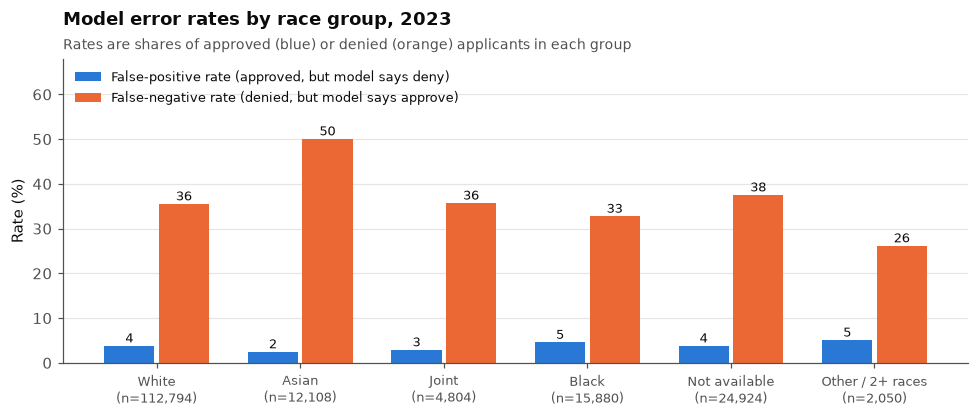

In [14]:
plot = ft.loc[["White", "Asian", "Joint", "Black", "Not available", "Other / 2+ races"], ["FPR", "FNR"]]
fig, ax = plt.subplots(figsize=(9, 3.9)); w = 0.38; xs = np.arange(len(plot))
ax.bar(xs - w / 2, plot.FPR, w * 0.92, color=BLUE, label="False-positive rate (approved, but model says deny)")
ax.bar(xs + w / 2, plot.FNR, w * 0.92, color=ORANGE, label="False-negative rate (denied, but model says approve)")
for x, a, b in zip(xs, plot.FPR, plot.FNR):
    ax.text(x - w / 2, a + 0.8, f"{a:.0f}", ha="center", fontsize=8.5); ax.text(x + w / 2, b + 0.8, f"{b:.0f}", ha="center", fontsize=8.5)
ax.set_xticks(xs); ax.set_xticklabels([f"{i}\n(n={int(ft.loc[i,'n']):,})" for i in plot.index], fontsize=8.5)
ax.set_ylabel("Rate (%)"); ax.set_ylim(0, 68); ax.grid(axis="x", visible=False); ax.legend(frameon=False, fontsize=8.5, loc="upper left")
finish(ax, "Model error rates by race group, 2023", "Rates are shares of approved (blue) or denied (orange) applicants in each group", "18_fairness_errors")

In [15]:
big = ft.drop(index="White")
big = big[big.n >= 1000]
flag = []
for g, r in big.iterrows():
    for m in ["error_rate", "FPR", "FNR"]:
        if r[f"{m}_gap_pp"] > 5 and r[f"{m}_lo"] > 0:
            flag.append((g, m, round(r[f"{m}_gap_pp"], 1)))
V6 = "Supported" if flag else "Not supported"
print("Group/metric pairs with a significant gap > 5 pp vs White:", flag if flag else "none")
print("H6 ->", V6)

# 80% rule on approval rates (approve = model says not-deny)
appr = 1 - ft.pred_denial_rate / 100
print("\nModel approval-rate ratio vs White (80% rule: flag if below 0.80):")
print((appr / appr["White"]).round(2).to_string())

Group/metric pairs with a significant gap > 5 pp vs White: [('Asian', 'FNR', np.float64(14.5))]
H6 -> Supported

Model approval-rate ratio vs White (80% rule: flag if below 0.80):
group
Asian               1.05
Black               0.89
Joint               1.01
Not available       0.97
Other / 2+ races    0.87
White               1.00


**How to read the H6 result.** The rule is applied mechanically, but the substance matters for the stakeholder:
* We ran several comparisons (3 error measures x each group), so one or two 'significant' gaps are expected by chance alone; a gap in a small group is also less stable.
* The flagged gap is the **false-negative rate for Asian applicants**: the model misses more of the denials in that group. It is not a case of the model denying a protected group more often.
* For **Black applicants** the error-rate gap is below 5 pp and the model's approval rate is above the 80% rule threshold, so the model does not widen the raw gap seen in the data.
* All of this compares the model with **past decisions**, which may themselves contain bias.

### H6 - extra check (not part of the pre-set rule): does the fairness finding depend on the threshold?
The audit above uses one threshold. Here we repeat it at several; if a 'significant gap > 5 pp' appears or disappears as the threshold moves, the finding is fragile.

In [16]:
rows = []
for t in [0.20, 0.25, THR, 0.40, 0.50]:
    test["pred_t"] = (test.p >= t).astype(int)
    ftt = fairness_table(test, "pred_t")
    bg = ftt.drop(index="White"); bg = bg[bg.n >= 1000]
    fl = [(g, m, round(float(r[f"{m}_gap_pp"]), 1)) for g, r in bg.iterrows()
          for m in ["error_rate", "FPR", "FNR"] if r[f"{m}_gap_pp"] > 5 and r[f"{m}_lo"] > 0]
    rows.append(dict(threshold=round(t, 2), significant_gaps_over_5pp=fl if fl else "none",
                     black_vs_white_error_gap_pp=round(float(ftt.loc["Black", "error_rate_gap_pp"]), 1)))
display(pd.DataFrame(rows))

,threshold,significant_gaps_over_5pp,black_vs_white_error_gap_pp
0,0.20,"[(Asian, FNR, 14.9)]",4.1
1,0.25,"[(Asian, FNR, 15.4)]",4.0
2,0.31,"[(Asian, FNR, 14.5)]",4.2
3,0.40,"[(Asian, FNR, 13.7)]",4.6
4,0.50,"[(Asian, FNR, 13.3), (Black, error_rate, 5.0)]",5.0


## 7. Bias mitigation: reweighing
**Idea (Kamiran & Calders):** give each training example a weight so that race and the denial outcome look statistically independent in the training data: `w(group, y) = P(group) * P(y) / P(group, y)`. Race is used only to compute these weights, **not** as a model input. We then check whether the gaps shrink and what it costs in accuracy.

In [17]:
g = fit_all.race_grp.where(fit_all.race_grp.isin(["White", "Black", "Asian"]), "Other")
pg, py = g.value_counts(normalize=True), fit_all.denied.value_counts(normalize=True)
pgy = pd.crosstab(g, fit_all.denied, normalize=True)
w = np.array([pg[a] * py[b] / pgy.loc[a, b] for a, b in zip(g, fit_all.denied)])
print("Weight range:", w.min().round(2), "to", w.max().round(2))

mit = lgb.train(BEST, make_set(fit_all, w), num_boost_round=N_TREES)
test["p_m"] = mit.predict(test[FEATURES])
pv_m = lgb.train(BEST, make_set(train, w[(fit_all.year <= 2021).values]), num_boost_round=int(best.trees)).predict(valid[FEATURES])
THR_M = float(grid[int(np.argmax([f1_score(valid.denied, pv_m >= t) for t in grid]))])
test["pred_m"] = (test.p_m >= THR_M).astype(int)
fm = fairness_table(test, "pred_m")

cmp = pd.DataFrame({
    "FPR gap Black-White (pp)": [ft.loc["Black", "FPR_gap_pp"], fm.loc["Black", "FPR_gap_pp"]],
    "FNR gap Black-White (pp)": [ft.loc["Black", "FNR_gap_pp"], fm.loc["Black", "FNR_gap_pp"]],
    "Error gap Black-White (pp)": [ft.loc["Black", "error_rate_gap_pp"], fm.loc["Black", "error_rate_gap_pp"]],
    "AUC (all rows)": [auc(test.denied, test.p), auc(test.denied, test.p_m)],
    "AUC (complete)": [auc(tc.denied, tc.p), auc(test[test.complete].denied, test[test.complete].p_m)],
    "Overall accuracy": [(test.pred == test.denied).mean(), (test.pred_m == test.denied).mean()],
}, index=["Standard model", "Reweighed model"]).T
display(cmp.round(3))

Weight range: 0.54 to 1.25


,Standard model,Reweighed model
FPR gap Black-White (pp),0.778,0.649
FNR gap Black-White (pp),-2.776,-2.333
Error gap Black-White (pp),4.164,4.254
AUC (all rows),0.880,0.879
AUC (complete),0.825,0.824
Overall accuracy,0.914,0.914


## 8. Choosing a threshold (recommendation for the lender)
Different cut-offs trade off *denying good applicants* against *approving risky ones*. The table shows, on 2023, what each threshold would do.

In [18]:
rows = []
for t in [0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]:
    pr = (tc.p >= t).astype(int); y = tc.denied
    rows.append(dict(threshold=t, share_flagged_deny=pr.mean() * 100, precision=precision_score(y, pr) * 100,
                     recall=recall_score(y, pr) * 100, approved_but_flagged_pct=((pr == 1) & (y == 0)).sum() / (y == 0).sum() * 100))
thr = pd.DataFrame(rows).set_index("threshold").round(1)
thr.columns = ["% of applications flagged", "precision %", "recall %", "% of approved flagged (FPR)"]
display(thr)
print(f"Threshold chosen on validation data (max F1): {THR:.2f}")

,% of applications flagged,precision %,recall %,% of approved flagged (FPR)
threshold,,,,
0.10,20.2,33.5,64.9,15.0
0.15,10.7,52.3,53.6,5.7
0.20,8.2,63.0,49.2,3.4
0.25,7.1,68.7,46.8,2.5
0.30,6.6,71.8,45.5,2.1
0.40,5.9,75.6,43.1,1.6
0.50,5.1,80.4,39.3,1.1


Threshold chosen on validation data (max F1): 0.31


## 9. Save model and results

In [19]:
final.save_model(str(MODELS / "lgbm_denial.txt"))
card = dict(features=FEATURES, categorical=CATEG, threshold=THR, trained_on="2018-2022", tested_on="2023",
            auc_all_rows=float(res.loc["all test rows", "auc"]), auc_complete_cases=float(AUC_C),
            excluded_on_purpose=["race", "ethnicity", "sex", "age", "tract minority share", "post-decision pricing columns"],
            categories={c: list(df[c].cat.categories) for c in CATEG}, medians={c: float(df[c].median()) for c in NUMERIC})
(MODELS / "model_card.json").write_text(json.dumps(card, indent=2))

r = pd.read_csv(ROOT / "reports" / "hypothesis_results.csv")
r = r[~r.hypothesis.isin(["H5", "H6"])]
new = pd.DataFrame([
    dict(hypothesis="H5", method="LightGBM (train 2018-22, test 2023) + SHAP", estimate=f"AUC {AUC_C:.3f} (complete cases); top-3: {', '.join(top3)}",
         ci_95=f"{AUC_LO:.3f} to {AUC_HI:.3f}", p_value=np.nan, verdict=V5,
         note=f"AUC judged on complete cases to avoid missing-value leakage. Sensitivity without preapproval flag: AUC {S_AUC:.3f}, top-3 {S_TOP3}."),
    dict(hypothesis="H6", method="Group error rates (FPR/FNR/error) vs White, 95% CI", estimate=str(flag) if flag else "no gap > 5 pp",
         ci_95="see notebook", p_value=np.nan, verdict=V6, note=f"Audit vs historical decisions; race not an input. {len(big)*3} comparisons, {len(flag)} significant gap(s) > 5 pp.")])
r = pd.concat([r, new]).sort_values("hypothesis")
r.to_csv(ROOT / "reports" / "hypothesis_results.csv", index=False)
display(r[["hypothesis", "estimate", "verdict"]])

,hypothesis,estimate,verdict
0,H1,-0.50 pp,Not supported
1,H2,OR 1.73 (model B); PSM gap 4.71 pp,Supported
2,H3,OR 1.17; adj. gap 1.21 pp,Supported
3,H4,"r=0.73 (denial), r=0.23 (loan)",Inconclusive
0,H5,AUC 0.825 (complete cases); top-3: preapproval...,Inconclusive
1,H6,"[('Asian', 'FNR', np.float64(14.5))]",Supported
6,H7,OR 0.56; PSM gap -5.21 pp,Supported
